# Feed Amount Analysis (RF-DETR) - Log-Normal Kalman Filter

This notebook estimates feed consumption rate from per-frame RF-DETR bounding box areas.

**Theory:** RF-DETR detection noise is multiplicative (proportional to box size).
Taking `log(area)` converts it to additive Gaussian noise for optimal Kalman filtering.

Key features:
- 2D state vector: `[log_area, consumption_rate]`
- Unbiased area recovery: `exp(μ + P₁₁/2)`
- 1-sigma confidence interval from filter covariance
- True one-step-ahead prediction via constant-velocity model
- **Model:** RF-DETR (detects: debris, feed, fish, lumpfish)

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set default font
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

## 1. Kalman Filter Implementation

In [10]:
class LogNormalKalmanFilter:
    """
    2D Log-Normal Kalman Filter for feed area estimation with robust zero-handling.

    State vector: x = [mu, mu_dot]
      mu      = log(true feed area)
      mu_dot  = d(log A)/dt  [1/frame]

    When area=0 (detection gap): assume feed is decaying at predicted rate,
    use weak constraint with high uncertainty instead of hard zero.
    """

    def __init__(self, sigma_R: float = 0.15, sigma_Q: float = 1e-3, dt: float = 1.0, 
                 zero_decay_rate: float = -0.02):
        self.dt = dt
        self.sigma_R = sigma_R
        self.zero_decay_rate = zero_decay_rate  # log-space decay per frame when area=0
        self.x = np.zeros(2)
        self.P = np.eye(2)
        self.F = np.array([[1.0, dt], [0.0, 1.0]])
        self.h = np.array([1.0, 0.0])
        self.Q = sigma_Q * np.array([
            [dt ** 4 / 4, dt ** 3 / 2],
            [dt ** 3 / 2, dt ** 2    ]
        ])
        self.R_scalar = sigma_R ** 2
        self.initialized = False
        self.consecutive_zeros = 0

    def update(self, area_measurement: float) -> float:
        if not self.initialized:
            if area_measurement <= 0:
                return 0.0
            self.x = np.array([np.log(area_measurement), 0.0])
            self.P = np.diag([self.sigma_R ** 2, 1.0])
            self.initialized = True
            return self.area_estimate

        # Prediction step
        x_pred = self.F @ self.x
        P_pred = self.F @ self.P @ self.F.T + self.Q

        if area_measurement <= 0:
            # Detection gap: use weak decay constraint with high uncertainty
            self.consecutive_zeros += 1
            # Expected decay: use zero_decay_rate as weak prior
            expected_decay = self.zero_decay_rate * self.consecutive_zeros
            y = x_pred[0] + expected_decay
            # Very high measurement noise (low confidence in zero)
            R_zero = (10 * self.sigma_R) ** 2
            innovation = y - self.h @ x_pred
            S = self.h @ P_pred @ self.h + R_zero
            K = (P_pred @ self.h) / S
            self.x = x_pred + K * innovation
            self.P = (np.eye(2) - np.outer(K, self.h)) @ P_pred
        else:
            # Valid detection: standard Kalman update
            self.consecutive_zeros = 0
            y = np.log(area_measurement)
            innovation = y - self.h @ x_pred
            S = self.h @ P_pred @ self.h + self.R_scalar
            K = (P_pred @ self.h) / S
            self.x = x_pred + K * innovation
            self.P = (np.eye(2) - np.outer(K, self.h)) @ P_pred

        return self.area_estimate

    def predict_next(self) -> float:
        x_next = self.F @ self.x
        P_next = self.F @ self.P @ self.F.T + self.Q
        return np.exp(np.clip(x_next[0] + P_next[0, 0] / 2, -10, 15))

    @property
    def area_estimate(self) -> float:
        return np.exp(np.clip(self.x[0] + self.P[0, 0] / 2, -10, 15))

    @property
    def consumption_rate(self) -> float:
        return self.x[1]

    @property
    def area_confidence_interval(self):
        log_std = np.sqrt(self.P[0, 0])
        lower = np.exp(np.clip(self.x[0] - log_std, -10, 15))
        upper = np.exp(np.clip(self.x[0] + log_std, -10, 15))
        return lower, upper

## 2. Configuration Parameters

In [11]:
CONFIG = {
    'video_path': '../data/fish_feeding.mp4',
    'model_path': '../models/rf-detr-fish-regular.pth',
    'confidence_threshold': 0.3,
    'device': 'cuda',
    'sigma_R': 0.15,
    'sigma_Q': 1e-2,
    'max_frames': None,
}

print('Configuration parameters:')
for k, v in CONFIG.items():
    print(f'  {k}: {v}')

Configuration parameters:
  video_path: ../data/fish_feeding.mp4
  model_path: ../models/rf-detr-fish-regular.pth
  confidence_threshold: 0.3
  device: cuda
  sigma_R: 0.15
  sigma_Q: 0.01
  max_frames: None


## 3. Load RF-DETR Model and Video

In [12]:
from rfdetr.detr import RFDETR

print(f'加載模型: {CONFIG["model_path"]}')
model = RFDETR.from_checkpoint(CONFIG['model_path'])
model.device = CONFIG['device']

class_names = {0: 'debris', 1: 'feed', 2: 'fish', 3: 'lumpfish'}
print(f'類別: {class_names}')

video_path = CONFIG['video_path']
print(f'\\n加載視頻: {video_path}')
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError(f'無法打開視頻: {video_path}')

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f'視頻信息:')
print(f'  總幀數: {total_frames}')
print(f'  FPS: {fps}')
print(f'  解像度: {width}x{height}')
print(f'  總時長: {total_frames/fps:.2f}秒')

[2026-05-24 17:03:50] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-05-24 17:03:50] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


加載模型: ../models/rf-detr-fish-regular.pth


[2026-05-24 17:03:51] [WARNING] rf-detr - Checkpoint has 4 classes but model is configured for 90. Using checkpoint class count (4). Pass num_classes=4 to suppress this warning.
[2026-05-24 17:03:51] [WARNING] rf-detr - load_pretrain_weights: args.num_queries absent; inferred ckpt_num_queries=300 from tensor rows 3900 ÷ ckpt_group_detr=13.


類別: {0: 'debris', 1: 'feed', 2: 'fish', 3: 'lumpfish'}
\n加載視頻: ../data/fish_feeding.mp4
視頻信息:
  總幀數: 563
  FPS: 30.0
  解像度: 1920x1080
  總時長: 18.77秒


## 4. Run Inference and Calculate Feed Area (RF-DETR Only)

In [13]:
frame_numbers    = []
feed_areas_raw   = []
feed_areas_filtered = []
consumption_rates   = []
predictions      = []
conf_upper       = []
conf_lower       = []

kf = LogNormalKalmanFilter(
    sigma_R=CONFIG['sigma_R'],
    sigma_Q=CONFIG['sigma_Q'],
    dt=1.0,
)

frame_idx  = 0
max_frames = CONFIG['max_frames'] or total_frames

print(f'開始推論，共 {min(max_frames, total_frames)} 幀...')
print(f'信心度閾值: {CONFIG["confidence_threshold"]}')
print(f'sigma_R={CONFIG["sigma_R"]},  sigma_Q={CONFIG["sigma_Q"]}')
print()

開始推論，共 563 幀...
信心度閾值: 0.3
sigma_R=0.15,  sigma_Q=0.01



In [14]:
import sys

# 新增诊断变量
frames_with_detections = []
frames_with_feed = []
feed_detections_per_frame = []
feed_confidence_per_frame = []
feed_sizes_per_frame = []

while frame_idx < max_frames:
    ret, frame = cap.read()
    if not ret:
        print(f'\n到達視頻末尾在 Frame {frame_idx}')
        break

    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    detections = model.predict(rgb_frame, threshold=CONFIG['confidence_threshold'])
    
    frame_feed_area = 0.0
    frame_feed_count = 0
    frame_feed_confs = []
    frame_feed_sizes = []
    
    if detections is not None and len(detections) > 0:
        frames_with_detections.append(frame_idx)
        # 打印前5帧的检测结果
        if frame_idx < 5:
            print(f'\nFrame {frame_idx}: 检测到 {len(detections)} 个对象')
            for box, cls_id, conf in zip(detections.xyxy, detections.class_id, detections.confidence):
                print(f'  Class {cls_id} ({class_names[cls_id]}): conf={conf:.3f}')
        
        for box, cls_id, conf in zip(detections.xyxy, detections.class_id, detections.confidence):
            if cls_id == 1:  # feed class
                x1, y1, x2, y2 = box
                area = (x2 - x1) * (y2 - y1)
                frame_feed_area += area
                frame_feed_count += 1
                frame_feed_confs.append(conf)
                frame_feed_sizes.append(area)
    
    if frame_feed_count > 0:
        frames_with_feed.append(frame_idx)
    
    feed_detections_per_frame.append(frame_feed_count)
    feed_confidence_per_frame.append(frame_feed_confs)
    feed_sizes_per_frame.append(frame_feed_sizes)

    frame_numbers.append(frame_idx)
    feed_areas_raw.append(frame_feed_area)

    filtered = kf.update(frame_feed_area)
    feed_areas_filtered.append(filtered)
    consumption_rates.append(kf.consumption_rate)
    predictions.append(kf.predict_next())

    lo, hi = kf.area_confidence_interval
    conf_lower.append(lo)
    conf_upper.append(hi)

    if (frame_idx + 1) % 100 == 0:
        sys.stdout.write(f'\r已處理: {frame_idx + 1}/{min(max_frames, total_frames)} 幀')
        sys.stdout.flush()

    frame_idx += 1

cap.release()
print(f'\n\n推論完成！共處理 {len(frame_numbers)} 幀')

# 诊断输出
print(f'\n【RF-DETR 檢測診斷】')
print(f'有檢測結果的幀數: {len(frames_with_detections)}/{len(frame_numbers)} ({len(frames_with_detections)/len(frame_numbers)*100:.1f}%)')
print(f'檢測到 feed 的幀數: {len(frames_with_feed)}/{len(frame_numbers)} ({len(frames_with_feed)/len(frame_numbers)*100:.1f}%)')
print(f'平均每幀 feed 檢測數: {np.mean(feed_detections_per_frame):.2f}')
print(f'最多一幀 feed 檢測數: {np.max(feed_detections_per_frame)}')

# 统计feed的信心度
all_feed_confs = [c for confs in feed_confidence_per_frame for c in confs]
if all_feed_confs:
    print(f'\nFeed 檢測信心度統計:')
    print(f'  最小值: {np.min(all_feed_confs):.3f}')
    print(f'  最大值: {np.max(all_feed_confs):.3f}')
    print(f'  平均值: {np.mean(all_feed_confs):.3f}')
    print(f'  標準差: {np.std(all_feed_confs):.3f}')


[2026-05-24 17:03:52] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. You can optimize the model for inference by calling model.optimize_for_inference().
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!



Frame 0: 检测到 6 个对象
  Class 2 (fish): conf=0.732
  Class 2 (fish): conf=0.667
  Class 2 (fish): conf=0.425
  Class 1 (feed): conf=0.420
  Class 1 (feed): conf=0.357
  Class 1 (feed): conf=0.341

Frame 1: 检测到 8 个对象
  Class 2 (fish): conf=0.659
  Class 2 (fish): conf=0.613
  Class 2 (fish): conf=0.609
  Class 3 (lumpfish): conf=0.487
  Class 1 (feed): conf=0.487
  Class 1 (feed): conf=0.399
  Class 1 (feed): conf=0.394
  Class 1 (feed): conf=0.328

Frame 2: 检测到 8 个对象
  Class 2 (fish): conf=0.740
  Class 2 (fish): conf=0.604
  Class 1 (feed): conf=0.469
  Class 1 (feed): conf=0.387
  Class 1 (feed): conf=0.384
  Class 2 (fish): conf=0.381
  Class 1 (feed): conf=0.381
  Class 3 (lumpfish): conf=0.331

Frame 3: 检测到 6 个对象
  Class 2 (fish): conf=0.610
  Class 1 (feed): conf=0.513
  Class 1 (feed): conf=0.364
  Class 1 (feed): conf=0.354
  Class 2 (fish): conf=0.347
  Class 1 (feed): conf=0.319

Frame 4: 检测到 5 个对象
  Class 1 (feed): conf=0.680
  Class 2 (fish): conf=0.430
  Class 2 (fish): conf

## 5. Data Statistics

In [15]:
feed_areas_raw      = np.array(feed_areas_raw)
feed_areas_filtered = np.array(feed_areas_filtered)
consumption_rates   = np.array(consumption_rates)
predictions         = np.array(predictions)
conf_lower          = np.array(conf_lower)
conf_upper          = np.array(conf_upper)
frame_numbers       = np.array(frame_numbers)

print('=' * 65)
print('飼料面積統計 (RF-DETR)')
print('=' * 65)

print('\\n原始值 (RF-DETR 測量):')
print(f'  最小值: {feed_areas_raw.min():,.0f} pixels²')
print(f'  最大值: {feed_areas_raw.max():,.0f} pixels²')
print(f'  平均值: {feed_areas_raw.mean():,.0f} pixels²')
print(f'  標準差: {feed_areas_raw.std():,.0f} pixels²')

print('\\nLog-Normal KF 濾波後 (無偏估計):')
print(f'  最小值: {feed_areas_filtered.min():,.0f} pixels²')
print(f'  最大值: {feed_areas_filtered.max():,.0f} pixels²')
print(f'  平均值: {feed_areas_filtered.mean():,.0f} pixels²')
print(f'  標準差: {feed_areas_filtered.std():,.0f} pixels²')

noise_reduction = (1 - feed_areas_filtered.std() / feed_areas_raw.std()) * 100 if feed_areas_raw.std() > 0 else 0
print(f'  降噪效果: {noise_reduction:.1f}%')

print('\\n飼料消耗速率 d(log A)/dt  [1/frame]:')
print(f'  均值:   {consumption_rates.mean():.5f}')
print(f'  標準差: {consumption_rates.std():.5f}')
print(f'  最小值: {consumption_rates.min():.5f}  (最快消耗)')
print(f'  最大值: {consumption_rates.max():.5f}  (最快增加)')

pct_per_frame = consumption_rates.mean() * 100
pct_per_sec   = pct_per_frame * fps
print(f'\\n  平均 {pct_per_frame:.3f}% / frame  →  {pct_per_sec:.2f}% / sec')

飼料面積統計 (RF-DETR)
\n原始值 (RF-DETR 測量):
  最小值: 0 pixels²
  最大值: 1,233,303 pixels²
  平均值: 168,422 pixels²
  標準差: 255,260 pixels²
\nLog-Normal KF 濾波後 (無偏估計):
  最小值: 4 pixels²
  最大值: 3,269,017 pixels²
  平均值: 178,810 pixels²
  標準差: 294,048 pixels²
  降噪效果: -15.2%
\n飼料消耗速率 d(log A)/dt  [1/frame]:
  均值:   -0.00396
  標準差: 0.25272
  最小值: -0.79078  (最快消耗)
  最大值: 1.73676  (最快增加)
\n  平均 -0.396% / frame  →  -11.87% / sec


## 6. Visualization

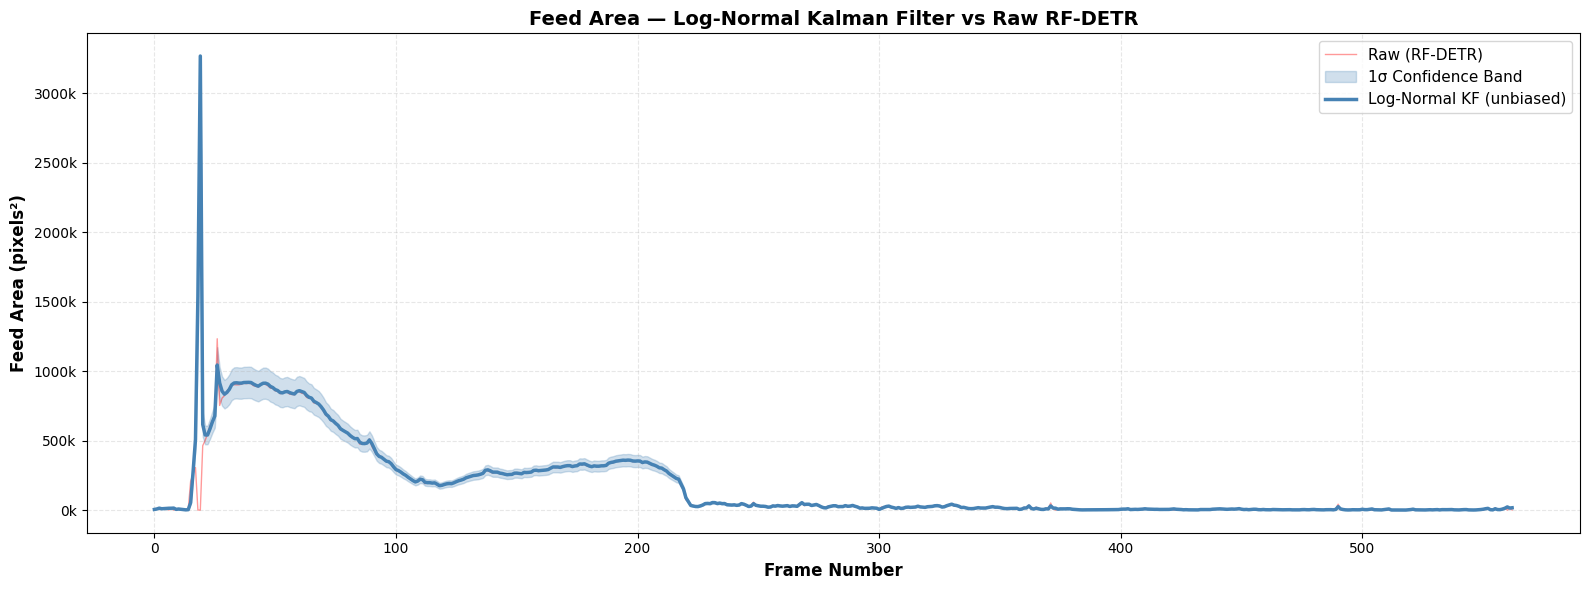

Saved: feed_amount_analysis_rfdetr.png


In [16]:
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(frame_numbers, feed_areas_raw,
        label='Raw (RF-DETR)', color='red', alpha=0.4, linewidth=1.0)
ax.fill_between(frame_numbers, conf_lower, conf_upper,
                alpha=0.25, color='steelblue', label='1σ Confidence Band')
ax.plot(frame_numbers, feed_areas_filtered,
        label='Log-Normal KF (unbiased)', color='steelblue', linewidth=2.5)

ax.set_xlabel('Frame Number', fontsize=12, fontweight='bold')
ax.set_ylabel('Feed Area (pixels²)', fontsize=12, fontweight='bold')
ax.set_title('Feed Area — Log-Normal Kalman Filter vs Raw RF-DETR', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3, linestyle='--')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

plt.tight_layout()
plt.savefig('feed_amount_analysis_rfdetr.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: feed_amount_analysis_rfdetr.png')

## 7. Export Results

In [17]:
import pandas as pd

results_df = pd.DataFrame({
    'Frame':                frame_numbers,
    'Raw_Feed_Area':        feed_areas_raw,
    'Filtered_Feed_Area':   feed_areas_filtered,
    'Consumption_Rate':     consumption_rates,
    'Consumption_Rate_Pct': consumption_rates * 100,
    'Predicted_Feed_Area':  predictions,
    'Conf_Lower_1sigma':    conf_lower,
    'Conf_Upper_1sigma':    conf_upper,
    'Filtering_Error':      np.abs(feed_areas_raw - feed_areas_filtered),
})

csv_path = 'feed_amount_analysis_rfdetr_results.csv'
results_df.to_csv(csv_path, index=False)
print(f'Saved: {csv_path}')

print('\\nData preview (first 10 rows):')
print(results_df.head(10).to_string())

print('\\nSummary:')
print(results_df.describe())

Saved: feed_amount_analysis_rfdetr_results.csv
\nData preview (first 10 rows):
   Frame  Raw_Feed_Area  Filtered_Feed_Area  Consumption_Rate  Consumption_Rate_Pct  Predicted_Feed_Area  Conf_Lower_1sigma  Conf_Upper_1sigma  Filtering_Error
0      0    4227.230469         4275.055193          0.000000              0.000000          7057.190407        3638.410873        4911.340962        47.824724
1      1    7552.948242         7541.941674          0.556843             55.684285         13777.646433        6430.749122        8652.528484        11.006568
2      2   13425.568359        13483.202679          0.573260             57.325980         24448.305793       11646.764155       15318.852879        57.634319
3      3    6456.840820         9185.430256          0.049482              4.948185          9817.336515        8010.280407       10360.162965      2728.589435
4      4   11066.679688        10666.301849          0.104109             10.410919         12030.815501        9341.6793

## 8. Final Report

In [18]:
print('\\n' + '=' * 70)
print(' ' * 10 + '飼料量分析 — RF-DETR + Log-Normal KF 完整報告')
print('=' * 70)

print(f'\\n【基本信息】')
print(f'  視頻文件:     {CONFIG["video_path"]}')
print(f'  RF-DETR 模型: {CONFIG["model_path"]}')
print(f'  處理幀數:     {len(frame_numbers)}')
print(f'  視頻時長:     {len(frame_numbers)/fps:.2f} 秒')
print(f'  信心度閾值:   {CONFIG["confidence_threshold"]}')

print(f'\\n【模型參數】')
print(f'  sigma_R: {CONFIG["sigma_R"]} (測量噪聲)')
print(f'  sigma_Q: {CONFIG["sigma_Q"]} (過程噪聲)')

print(f'\\n【飼料面積統計】')
print(f'  原始值:   {feed_areas_raw.min():,.0f} ~ {feed_areas_raw.max():,.0f} pixels²')
print(f'  濾波後:   {feed_areas_filtered.min():,.0f} ~ {feed_areas_filtered.max():,.0f} pixels²')
print(f'  降噪效果: {noise_reduction:.1f}%')

print(f'\\n【消耗速率】')
print(f'  均值: {consumption_rates.mean()*100:.4f}% / frame')
print(f'  標準差: {consumption_rates.std()*100:.4f}% / frame')

print(f'\\n【輸出文件】')
print(f'  ✓ feed_amount_analysis_rfdetr.png')
print(f'  ✓ feed_amount_analysis_rfdetr_results.csv')

print('\\n' + '=' * 70)
print('分析完成！')
print('=' * 70)

\n======================================================================
          飼料量分析 — RF-DETR + Log-Normal KF 完整報告
\n【基本信息】
  視頻文件:     ../data/fish_feeding.mp4
  RF-DETR 模型: ../models/rf-detr-fish-regular.pth
  處理幀數:     563
  視頻時長:     18.77 秒
  信心度閾值:   0.3
\n【模型參數】
  sigma_R: 0.15 (測量噪聲)
  sigma_Q: 0.01 (過程噪聲)
\n【飼料面積統計】
  原始值:   0 ~ 1,233,303 pixels²
  濾波後:   4 ~ 3,269,017 pixels²
  降噪效果: -15.2%
\n【消耗速率】
  均值: -0.3958% / frame
  標準差: 25.2716% / frame
\n【輸出文件】
  ✓ feed_amount_analysis_rfdetr.png
  ✓ feed_amount_analysis_rfdetr_results.csv
\n======================================================================
分析完成！
